# BÀI THỰC HÀNH CHƯƠNG 2 (PHẦN 2): CANNY EDGE DETECTOR

---

**Mục tiêu**:
1. Sử dụng **Canny Edge Detector** bằng hai thư viện OpenCV và scikit-image.
2. Khảo sát ảnh hưởng của **sigma**, **ngưỡng thấp** và **ngưỡng cao** đến kết quả phát hiện biên.
3. Áp dụng Canny trên ảnh **nhiều nhiễu**, **tương phản thấp** và **nhiều chi tiết**.
4. So sánh kết quả trước và sau **tiền xử lý ảnh** bằng median, bilateral và cân bằng histogram.
5. Tìm hiểu cách kết hợp Canny với **phân đoạn ảnh** và **nhận dạng hình dạng**.

## 📋 Bảng Lộ Trình Thực Thi Chuẩn Hóa (Execution Roadmap)

| Step | Description | What it does | Import path |
| :---: | :--- | :--- | :--- |
| **1** | **Setup & Nạp ảnh** | Nạp thư viện, cấu hình và ảnh grayscale mẫu | `skimage.data`, `yaml` |
| **2** | **Canny Libraries & Geometric Waveforms (YC1)** | Chạy Canny OpenCV/scikit-image, Quiver ROI, Sector Map, NMS 1D Ridge | [`src/labs/lab03_canny/visuals.py`](../../src/labs/lab03_canny/visuals.py) |
| **3** | **Sigma Tuning & 1D Tradeoff (YC2)** | Thay đổi sigma và phân tích đánh đổi Gaussian 1D (nhiễu vs dạt biên) | [`src/labs/lab03_canny/visuals.py`](../../src/labs/lab03_canny/visuals.py) |
| **4** | **Threshold Tuning & Hysteresis (YC2)** | Thử nghiệm cặp ngưỡng, biểu đồ CDF độ lớn và phân loại 3 màu Hysteresis | [`src/labs/lab03_canny/visuals.py`](../../src/labs/lab03_canny/visuals.py) |
| **5** | **Preprocessing & CLAHE Mechanism (YC3)** | Median, Bilateral, và cơ chế giới hạn độ dốc CLAHE trên ô cục bộ | [`src/labs/lab03_canny/visuals.py`](../../src/labs/lab03_canny/visuals.py) |
| **6** | **Segmentation (YC4)** | Canny → closing → tô đầy vùng kín | `cv2`, `scipy.ndimage` |
| **7** | **Shape Detection (YC4)** | HoughCircles tìm đồng xu hình tròn, đánh số và đếm | `cv2` |

---

### 🔗 Tài Liệu & Báo Cáo Kỹ Thuật Liên Quan (Documentation References)

- 📋 **Đặc Tả Yêu Cầu Bài Lab**: [`docs/labs/lab03/LAB_03_DESCRIPTION.md`](../../docs/labs/lab03/LAB_03_DESCRIPTION.md)
- 📄 **Báo Cáo Kỹ Thuật Chi Tiết**: [`docs/labs/lab03/LAB_03_REPORT.md`](../../docs/labs/lab03/LAB_03_REPORT.md)
- 🌐 **Báo Cáo Trực Quan HTML**: [`docs/labs/lab03/LAB_03_REPORT.html`](../../docs/labs/lab03/LAB_03_REPORT.html)
- 🏠 **Tài Liệu Toàn Dự Án**: [`README.md`](../../README.md)

## 0. Chuẩn Bị: Nạp Thư Viện & Ảnh Mẫu

Nạp các thư viện cốt lõi, đọc cấu hình và nạp ảnh mẫu **grayscale** từ scikit-image để dùng cho các bài thực hành Canny.

Ảnh `camera` dùng cho so sánh và khảo sát tham số; ảnh `brick` dùng cho trường hợp nhiều chi tiết. Ảnh đầu vào có dạng `(H, W)`, kiểu `uint8`; canvas màu trong phần hình học dùng **RGB**.

Hàm hỗ trợ `show_grid`: hiển thị dãy ảnh và kết quả biên trên một lưới có chú thích.

Cấu hình nằm tại [`configs/experiment/lab03_canny.yaml`](../../configs/experiment/lab03_canny.yaml). Chạy các cell từ trên xuống hoặc chọn **Restart Kernel → Run All**.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from skimage import data, feature, util

root = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.labs.lab03_canny import (
    canny_advanced,
    canny_core,
    canny_downstream,
    canny_metrics,
    canny_wrappers,
    visuals,
)

config = yaml.safe_load(
    (root / "configs/experiment/lab03_canny.yaml").read_text(encoding="utf-8")
)
params = config["default_params"]
settings = config["notebook"]
sigma = params["sigma"]
low, high = params["low_threshold"], params["high_threshold"]
aperture = params["aperture_size"]
l2_gradient = settings["l2_gradient"]
radius = int(np.ceil(settings["gaussian_radius_sigmas"] * sigma))
ksize = 2 * radius + 1
plt.rcParams.update({"figure.dpi": 80, "image.interpolation": "nearest"})
print("[+] Đã nạp thành công atomic modules từ src.labs.lab03_canny: canny_core, canny_wrappers, canny_advanced, canny_downstream, canny_metrics, visuals")


[+] Đã nạp thành công atomic modules từ src.labs.lab03_canny: canny_core, canny_wrappers, canny_advanced, canny_downstream, canny_metrics, visuals


In [2]:
def show_grid(images: list[np.ndarray], titles: list[str], ncols: int = 3) -> None:
    """Display (H,W) uint8/bool images or (H,W,3) RGB uint8 images.

    Args:
        images: Images to display at their original intensity scale.
        titles: One title per image.
        ncols: Number of columns.

    Returns:
        None. Displays the figure inline.
    """
    if not images or len(images) != len(titles):
        raise ValueError("Cần cùng số ảnh và tiêu đề, không rỗng.")
    rows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        rows, ncols, figsize=(4.5 * ncols, 3.8 * rows), squeeze=False
    )
    for ax in axes.ravel():
        ax.axis("off")
    for ax, image, title in zip(axes.ravel(), images, titles, strict=False):
        ax.imshow(image, cmap="gray", vmin=0, vmax=1 if image.dtype == bool else 255)
        ax.set_title(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

Ảnh camera: shape=(512, 512), dtype=uint8


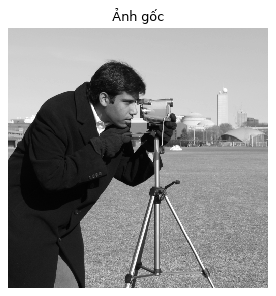

In [3]:
img = data.camera()
print(f"Ảnh camera: shape={img.shape}, dtype={img.dtype}")
show_grid([img], ["Ảnh gốc"], ncols=1)

## Yêu cầu 1: Phát Hiện Cạnh Bằng Hai Thư Viện

Dùng cùng ảnh đã nạp, gọi `cv2.Canny` và `skimage.feature.canny`, rồi hiển thị kết quả cạnh nhau.

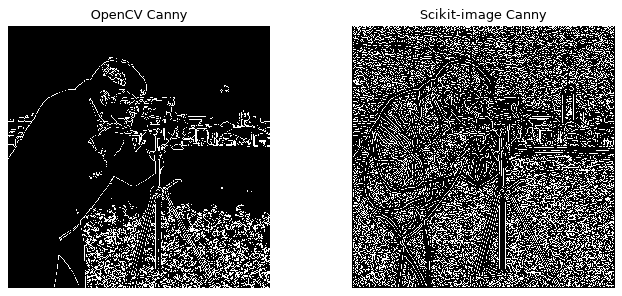

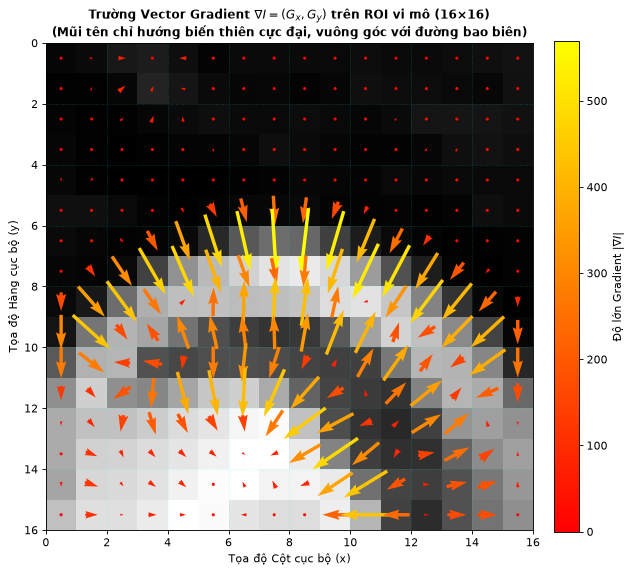

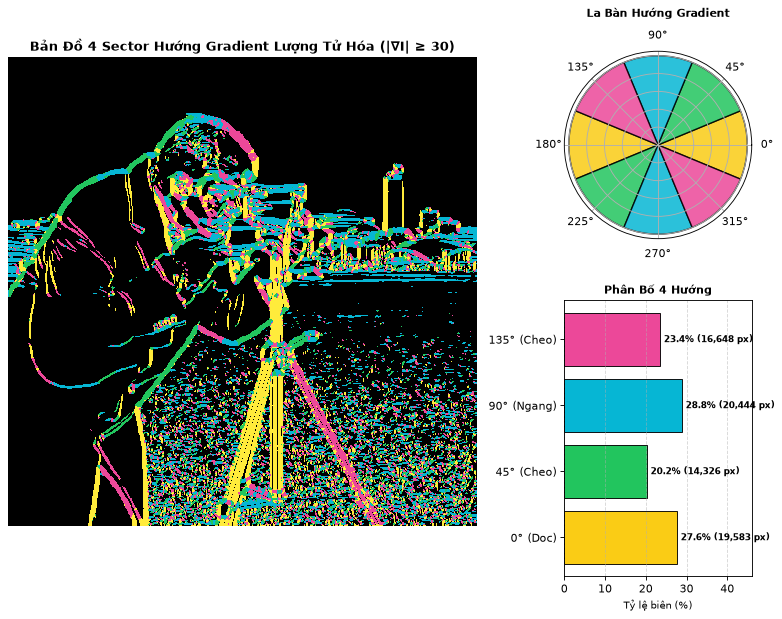

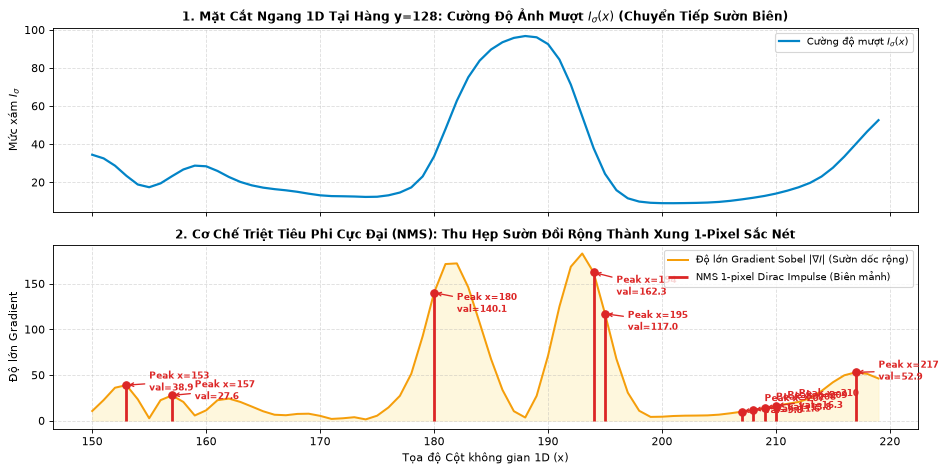

In [4]:
edges_cv = canny_wrappers.run_opencv_canny(img, low, high, aperture_size=aperture, l2_gradient=l2_gradient)
edges_sk = canny_wrappers.run_skimage_canny(
    img,
    sigma=sigma,
    low_threshold=low / 255.0,
    high_threshold=high / 255.0,
)
show_grid([edges_cv, edges_sk], ["OpenCV Canny", "Scikit-image Canny"], ncols=2)

# --- Visual Analytics (YC1): Quiver ROI, 4-Sector Directional Map, & NMS 1D Ridge Profile ---
visuals.plot_gradient_quiver_roi(img, y_slice=(120, 136), x_slice=(180, 196), step=1)
plt.show()

visuals.plot_sector_directional_map(img, threshold=30.0)
plt.show()

visuals.plot_nms_ridge_cross_section(img, row=128, col_start=150, col_end=220)
plt.show()


**Nhận xét:** OpenCV trả ảnh biên `uint8` (0/255), scikit-image trả mask `bool`. Lời gọi OpenCV ở đây không có bước Gaussian riêng; scikit-image làm mịn với `sigma=1`. Vì vậy kết quả khác nhau và đây là minh họa hai API, không phải so sánh độ chính xác với điều kiện xử lý giống hệt nhau.

## Yêu cầu 2: Thay Đổi Tham Số & Quan Sát Kết Quả

### 2.1. Sigma — mức làm mịn

Giữ ngưỡng 50/150, thử sigma 0.5, 1, 2, 3.5 từ config. Dải này giúp quan sát từ làm mịn nhẹ đến mạnh, không phải các giá trị tối ưu đã tìm được.

Chọn bán kính kernel khoảng `3σ` để chứa phần lớn trọng số Gaussian; kích thước luôn lẻ.

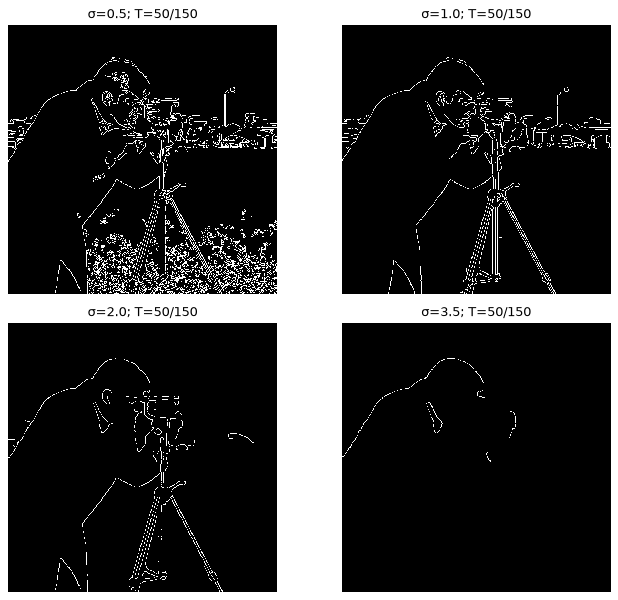

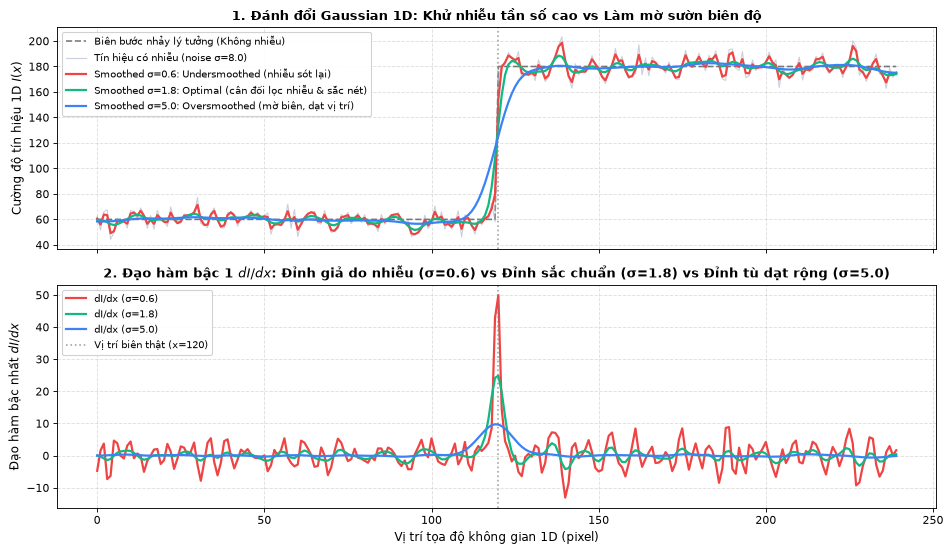

In [5]:
smoothed = cv2.GaussianBlur(img, (ksize, ksize), sigma)
sigma_images = []
sigmas = config["tuning_grid"]["sigmas"]
for value in sigmas:
    r = int(np.ceil(settings["gaussian_radius_sigmas"] * value))
    blurred = cv2.GaussianBlur(img, (2 * r + 1, 2 * r + 1), value)
    edges = cv2.Canny(blurred, low, high, apertureSize=aperture, L2gradient=l2_gradient)
    sigma_images.append(edges)
show_grid(sigma_images, [f"σ={value}; T={low}/{high}" for value in sigmas], ncols=2)

# --- Visual Analytics (YC2.1): 1D Gaussian Smoothing Tradeoff ---
visuals.plot_gaussian_tradeoff_1d(noise_sigma=8.0, sigmas=(0.6, 1.8, 5.0))
plt.show()


**Nhận xét:** khi sigma tăng, quan sát những chi tiết nhỏ biến mất và các đường viền còn lại. Làm mịn mạnh có thể giảm nhiễu nhưng cũng làm mất biên yếu.

### 2.2. Ngưỡng thấp và ngưỡng cao

Bốn ảnh dưới chạy OpenCV Canny trên **cùng ảnh đã làm mịn**, chỉ đổi hai ngưỡng:
- **30/90:** giữ nhiều biên yếu, thấy nhiều chi tiết nhỏ.
- **50/150:** bớt các biên yếu so với 30/90.
- **100/200:** khắt khe hơn, nhiều chi tiết nhỏ bị loại.
- **20/180:** cho phép biên yếu nối với biên mạnh; không có nghĩa mọi chi tiết đều được giữ.

Đây là phần thử tham số của **YC2**. Các nét trắng là biên được giữ, vùng đen là phần còn lại.

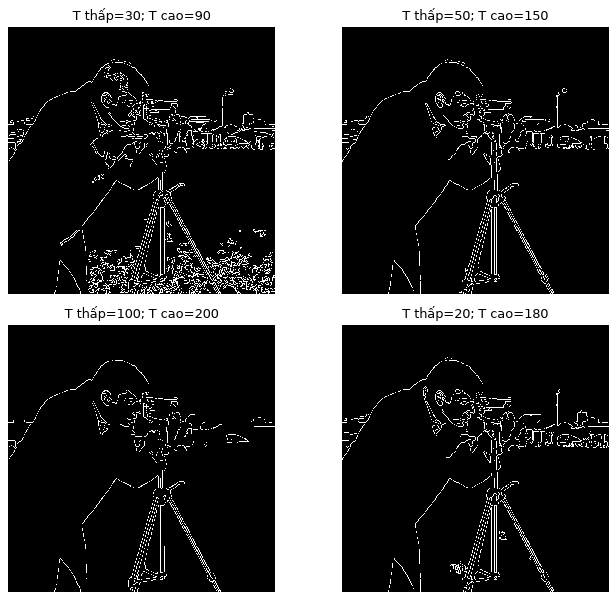

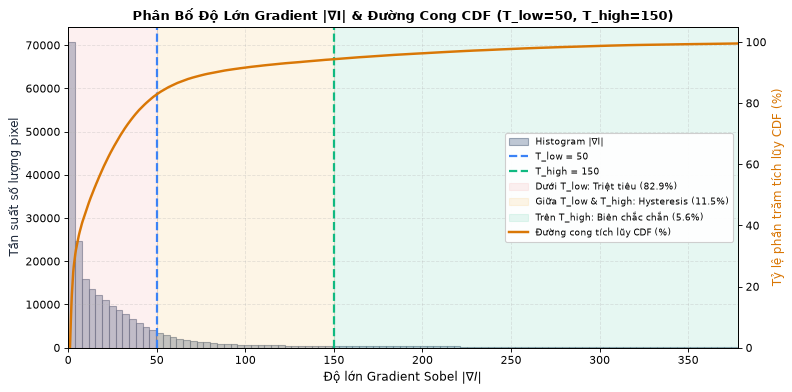

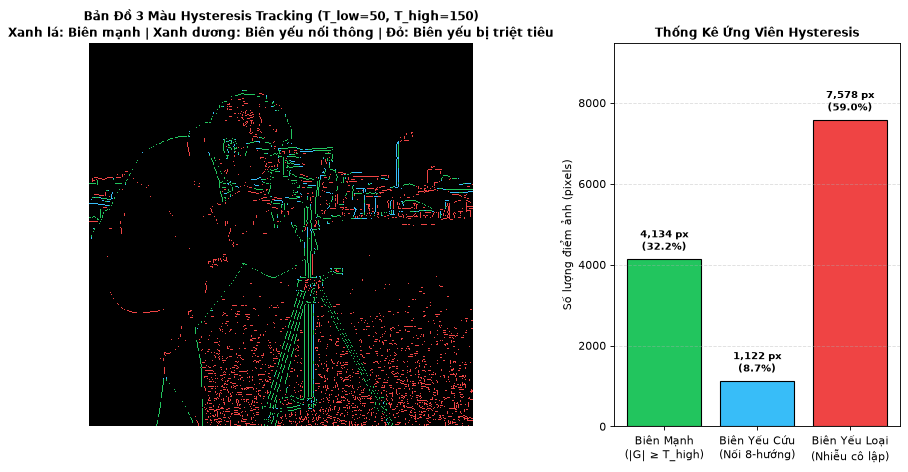

In [6]:
threshold_images = []
pairs = list(config["tuning_grid"]["threshold_pairs"].values())
for t_low, t_high in pairs:
    edges = cv2.Canny(
        smoothed, t_low, t_high, apertureSize=aperture, L2gradient=l2_gradient
    )
    threshold_images.append(edges)
show_grid(threshold_images, [f"T thấp={a}; T cao={b}" for a, b in pairs], ncols=2)

# --- Visual Analytics (YC2.2): Magnitude CDF Histogram & Tri-Color Hysteresis Map ---
visuals.plot_magnitude_cdf_histogram(img, low_thresh=low, high_thresh=high)
plt.show()

visuals.plot_hysteresis_tricolor(img, low_thresh=low, high_thresh=high)
plt.show()


**Nhận xét:** ngưỡng thấp dễ giữ nhiều ứng viên; ngưỡng cao nghiêm ngặt hơn với biên mạnh. So sánh độ liên tục của viền và lượng texture còn lại. Cần nhìn ảnh để chọn cấu hình phù hợp mục tiêu.

## Yêu cầu 3: Áp Dụng Canny Cho Các Loại Ảnh Khác Nhau

### 3.1. Ảnh nhiều nhiễu

Tạo nhiễu Gaussian với độ lệch chuẩn 20 và muối tiêu với xác suất 3%, seed cố định. Đây là lựa chọn minh họa trên thang cường độ 0–255.

Dùng bilateral cho nhiễu Gaussian và median 3×3 cho muối tiêu. Bilateral giữ tham số d=9, sigmaColor=50, sigmaSpace=5; sigmaColor đo khác biệt cường độ, sigmaSpace đo khoảng cách pixel. Hai tham số này khác sigma Gaussian của Canny.

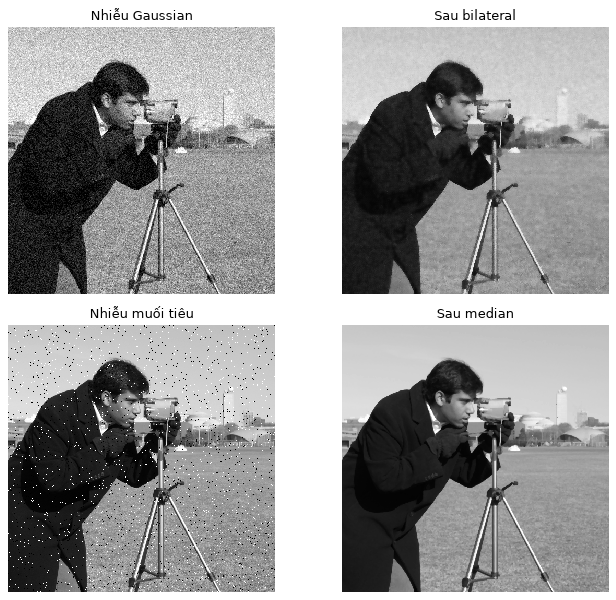

In [7]:
rng = np.random.default_rng(config["seed"])
gaussian_noisy = np.clip(
    img.astype(np.float32) + rng.normal(0, settings["noise_std"], img.shape), 0, 255
).astype(np.uint8)
salt_noisy = img.copy()
mask = rng.random(img.shape)
amount = settings["salt_pepper_amount"]
salt_noisy[mask < amount / 2] = 0
salt_noisy[mask > 1 - amount / 2] = 255
bilateral = cv2.bilateralFilter(gaussian_noisy, **settings["bilateral"])
median = cv2.medianBlur(salt_noisy, settings["median_ksize"])
show_grid(
    [gaussian_noisy, bilateral, salt_noisy, median],
    ["Nhiễu Gaussian", "Sau bilateral", "Nhiễu muối tiêu", "Sau median"],
    ncols=2,
)

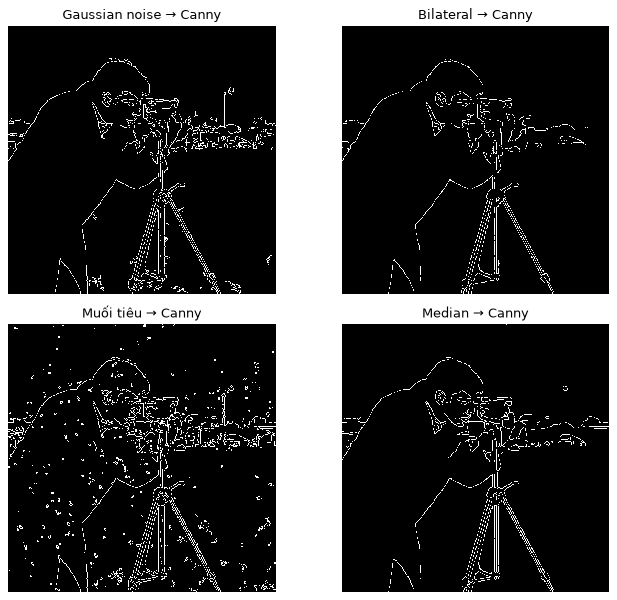

In [8]:
noise_edges = []
for image in [gaussian_noisy, bilateral, salt_noisy, median]:
    blurred = cv2.GaussianBlur(image, (ksize, ksize), sigma)
    noise_edges.append(
        cv2.Canny(blurred, low, high, apertureSize=aperture, L2gradient=l2_gradient)
    )
show_grid(
    noise_edges,
    [
        "Gaussian noise → Canny",
        "Bilateral → Canny",
        "Muối tiêu → Canny",
        "Median → Canny",
    ],
    ncols=2,
)

**Nhận xét:** đối chiếu các chấm biên giả trên nền và các đường viền chính. Median phù hợp với nhiễu xung; bilateral có thể làm mịn nhiễu và một phần chi tiết. Mỗi cặp dùng cùng sigma và ngưỡng Canny để thấy ảnh hưởng của tiền xử lý.

### 3.2. Ảnh tương phản thấp & Khắc phục hiện tượng loang lổ

Nén mức xám bằng `100 + 0.25 × ảnh`, tạo dải hẹp khoảng 100–163 (Canny trực tiếp mất 100% biên).
* **Cân bằng toàn cục (`cv2.equalizeHist`)**: Kéo giãn toàn ảnh nhưng gây ra hiện tượng **loang lổ (blotchy/patchy artifacts)**, khuếch đại nhiễu nền trời thành hàng ngàn biên giả.
* **Cân bằng thích ứng CLAHE (`cv2.createCLAHE`)**: Giới hạn độ tương phản cục bộ (`clipLimit=2.0`, `tileGridSize=(8, 8)`), giúp ảnh cân đối tự nhiên, khôi phục sắc nét biên chủ thể và khử sạch biên rác ở nền.

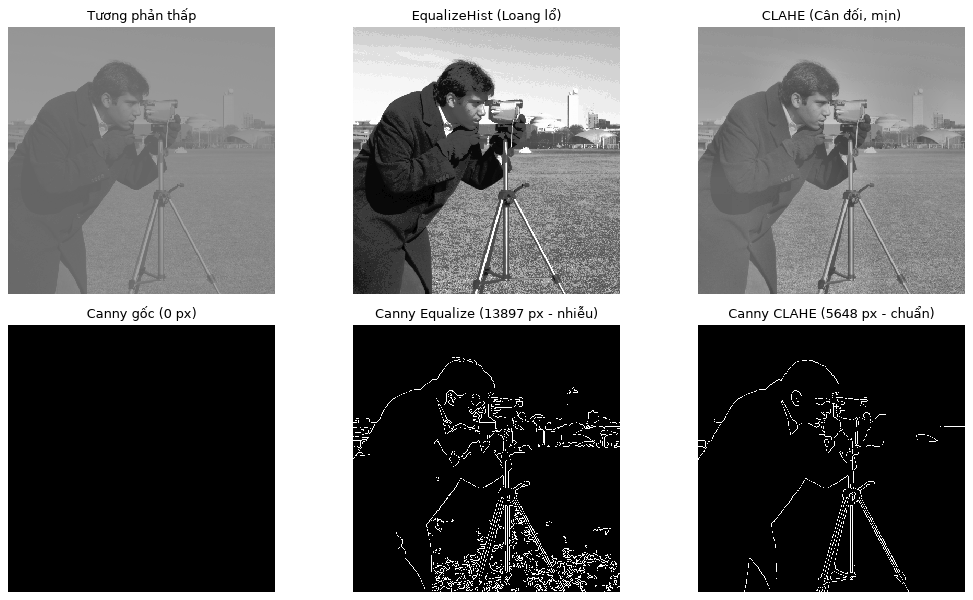

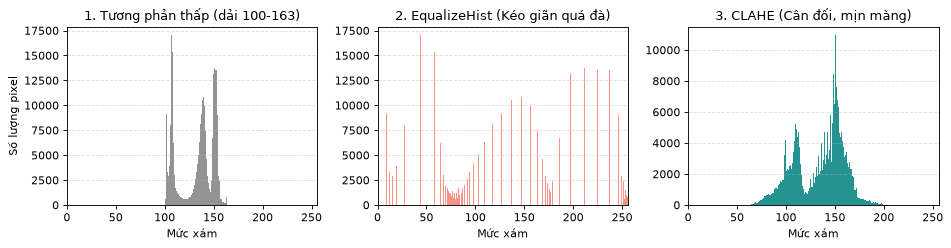

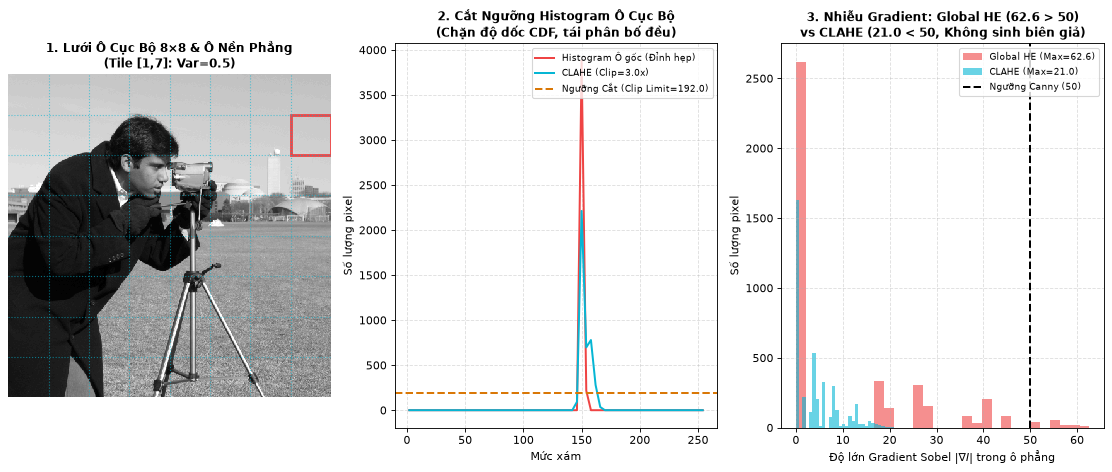

In [9]:
low_contrast = np.clip(
    settings["low_contrast_offset"]
    + settings["low_contrast_gain"] * img.astype(np.float32),
    0,
    255,
).astype(np.uint8)

# 1. Cân bằng toàn cục (Global Equalization) - nhược điểm: loang lổ nền
equalized = cv2.equalizeHist(low_contrast)

# 2. Cân bằng thích ứng CLAHE (Contrast Limited Adaptive) - khắc phục loang lổ
clahe_limit = config["preprocessing"]["low_contrast"].get("clahe_clip_limit", 2.0)
clahe_grid = tuple(config["preprocessing"]["low_contrast"].get("clahe_tile_grid_size", [8, 8]))
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=clahe_grid)
clahe_img = clahe.apply(low_contrast)

contrast_edges = []
for image in [low_contrast, equalized, clahe_img]:
    blurred = cv2.GaussianBlur(image, (ksize, ksize), sigma)
    contrast_edges.append(
        cv2.Canny(blurred, low, high, apertureSize=aperture, L2gradient=l2_gradient)
    )

show_grid(
    [low_contrast, equalized, clahe_img, *contrast_edges],
    [
        "Tương phản thấp",
        "EqualizeHist (Loang lổ)",
        "CLAHE (Cân đối, mịn)",
        f"Canny gốc ({np.count_nonzero(contrast_edges[0])} px)",
        f"Canny Equalize ({np.count_nonzero(contrast_edges[1])} px - nhiễu)",
        f"Canny CLAHE ({np.count_nonzero(contrast_edges[2])} px - chuẩn)",
    ],
    ncols=3,
)

# So sánh phân bố histogram của cả 3 phương pháp
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(low_contrast.ravel(), bins=256, range=[0, 256], color="gray", alpha=0.85)
axes[0].set_title("1. Tương phản thấp (dải 100-163)")
axes[0].set_xlim([0, 256])
axes[0].set_xlabel("Mức xám")
axes[0].set_ylabel("Số lượng pixel")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

axes[1].hist(equalized.ravel(), bins=256, range=[0, 256], color="salmon", alpha=0.85)
axes[1].set_title("2. EqualizeHist (Kéo giãn quá đà)")
axes[1].set_xlim([0, 256])
axes[1].set_xlabel("Mức xám")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

axes[2].hist(clahe_img.ravel(), bins=256, range=[0, 256], color="teal", alpha=0.85)
axes[2].set_title("3. CLAHE (Cân đối, mịn màng)")
axes[2].set_xlim([0, 256])
axes[2].set_xlabel("Mức xám")
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()
plt.close(fig)

# --- Visual Analytics (YC3.2): CLAHE Tile Mechanism & Contrast Slope Bounding ---
visuals.plot_clahe_tile_mechanism(low_contrast, clip_limit=clahe_limit, tile_grid_size=clahe_grid)
plt.show()


**Nhận xét so sánh:**
* `EqualizeHist toàn cục`: Đưa số pixel biên từ 0 lên 13.897, nhưng xuất hiện hiện tượng **loang lổ** rõ rệt trên bầu trời và bãi cỏ do biến thiên cường độ nhỏ bị kéo giãn quá mức, tạo thành "rừng biên rác".
* `CLAHE cục bộ`: Giới hạn mức tương phản cục bộ giúp phân bố sáng tối cân đối, giữ lại đúng **5.648 pixel biên** sắc nét của chủ thể (người, áo khoác, máy ảnh, chân giá đỡ) mà không làm loang lổ hay sinh biên giả ở hậu cảnh.

### 3.3. Ảnh nhiều chi tiết

Dùng ảnh tường gạch để so sánh Canny trước/sau bilateral. Cần xác định mình muốn giữ đường ron gạch hay cả texture trên bề mặt; nhiều biên không tự động có nghĩa là kết quả tốt.

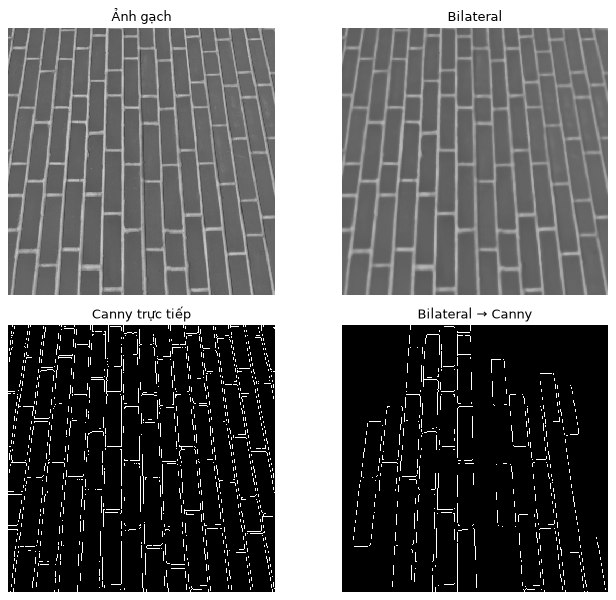

In [10]:
texture = data.brick()
texture_filtered = cv2.bilateralFilter(texture, **settings["bilateral"])
texture_edges = []
for image in [texture, texture_filtered]:
    blurred = cv2.GaussianBlur(image, (ksize, ksize), sigma)
    texture_edges.append(
        cv2.Canny(blurred, low, high, apertureSize=aperture, L2gradient=l2_gradient)
    )
show_grid(
    [texture, texture_filtered, *texture_edges],
    ["Ảnh gạch", "Bilateral", "Canny trực tiếp", "Bilateral → Canny"],
    ncols=2,
)

**Nhận xét:** quan sát texture bị giảm bao nhiêu và đường ron còn liên tục không. Các ảnh tự nhiên chưa có nhãn biên, nên bài này nhận xét trực quan, chưa báo độ chính xác hay F1.

## Yêu cầu 4: Kết Hợp Canny Với Các Kỹ Thuật Khác

### 4.1. Kết hợp phân đoạn để tìm các vùng trong ảnh

Dùng lại ảnh đồng xu `coins`: các vật có đường bao khá rõ và tách rời, phù hợp để quan sát cả vùng lẫn hình tròn.

**Luồng xử lý:** ảnh xám → Gaussian → Canny → closing nối khe hở nhỏ → tô đầy vùng kín.

Khác với phân ngưỡng cường độ, cách này tạo vùng từ **biên Canny**. `binary_fill_holes` tô phần bên trong biên kín để tạo mask đen–trắng, không tô màu lên vật.

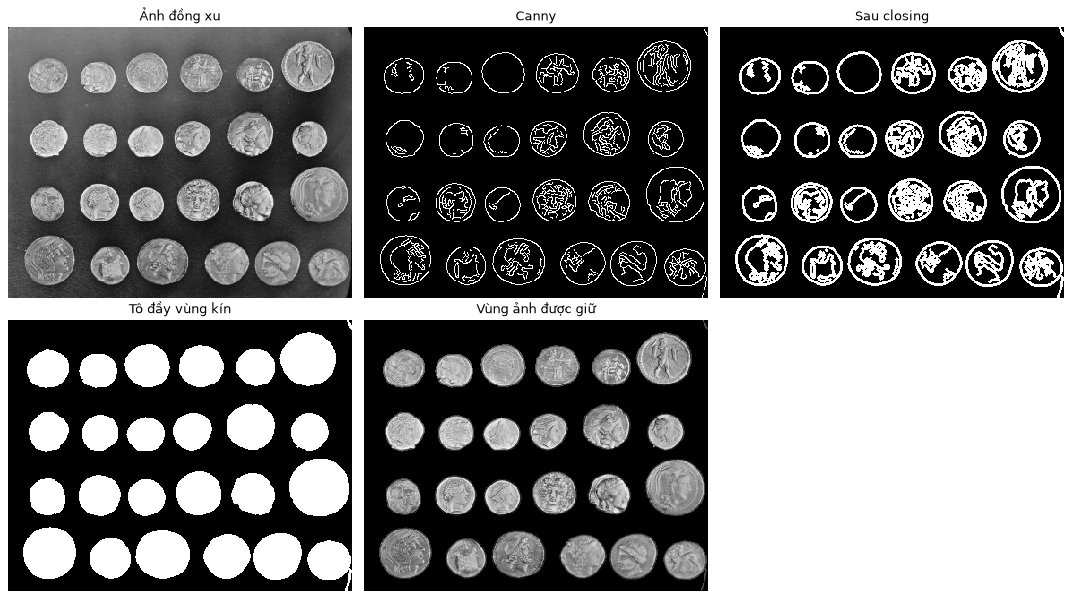

In [11]:
from scipy.ndimage import binary_fill_holes

region_image = data.coins()
segment_params = config["segmentation"]
morph_res = canny_downstream.segment_via_morphology_and_holes(
    region_image,
    low_threshold=low,
    high_threshold=high,
    gaussian_ksize=(ksize, ksize),
    gaussian_sigma=sigma,
    morph_kernel_size=tuple(segment_params["morph_kernel_size"]),
    closing_iterations=segment_params["closing_iterations"],
)

region_edges = morph_res["edges"]
region_closed = morph_res["closed"]
region_mask = morph_res["mask"]
region_result = morph_res["segmented"]

show_grid(
    [region_image, region_edges, region_closed, region_mask, region_result],
    ["Ảnh đồng xu", "Canny", "Sau closing", "Tô đầy vùng kín", "Vùng ảnh được giữ"],
    ncols=3,
)


**Tham số và nhận xét:** dùng kernel ellipse 3×3, closing một lần để nối khe hở nhỏ mà hạn chế nối các đồng xu gần nhau. Biên còn hở sẽ khiến tô vùng bỏ sót; biên nối nhầm có thể tạo vùng sai. Mask chỉ thể hiện vùng dự đoán, chưa khẳng định mọi pixel đều thuộc đồng xu. Không có nhãn chuẩn để báo độ chính xác.

### 4.2. Kết hợp Hough để tìm đối tượng hình tròn

**Mục tiêu:** tìm từng đồng xu, vẽ vòng tròn, đánh số và in số lượng.

`cv2.HoughCircles` nhận **ảnh xám đã làm mịn** và thực hiện xử lý gradient/Canny bên trong. Vì vậy không truyền mask biên Canny của mục 4.1 vào hàm này. `param1` là ngưỡng cao của Canny nội bộ; `param2` là ngưỡng quyết định tâm tròn của phương pháp `HOUGH_GRADIENT`.

Hough bổ sung bước nhận dạng hình học tròn cho bài thực hành.

Số hình tròn phát hiện được: 24


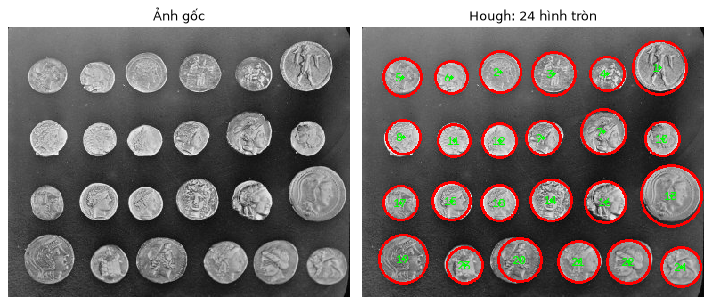

In [12]:
circle_params = config["shape_detection"]["hough_circles"]
hough_res = canny_downstream.detect_hough_circles(
    region_image,
    blur_ksize=tuple(circle_params["blur_ksize"]),
    blur_sigma=circle_params["blur_sigma"],
    dp=circle_params["dp"],
    min_dist=circle_params["min_dist"],
    param1=circle_params["param1"],
    param2=circle_params["param2"],
    min_radius=circle_params["min_radius"],
    max_radius=circle_params["max_radius"],
)

circle_result = hough_res["annotated_bgr"]
circles = hough_res["circles"]
circle_count = hough_res["count"]

print(f"Số hình tròn phát hiện được: {circle_count}")
show_grid(
    [region_image, cv2.cvtColor(circle_result, cv2.COLOR_BGR2RGB)],
    ["Ảnh gốc", f"Hough: {circle_count} hình tròn"],
    ncols=2,
)


**Lý do chọn tham số:** khoảng bán kính 15–40 pixel phù hợp kích thước đồng xu quan sát trên ảnh; `minDist=40` hạn chế tìm nhiều tâm sát nhau. Làm mịn 9×9, sigma=2 giảm texture mặt xu. `param1=100`, `param2=25` là cấu hình thử, không phải tham số tối ưu cho mọi ảnh.

Muốn tinh chỉnh, xem `shape_detection.hough_circles` trong YAML: tăng `param2` thường giữ ít ứng viên hơn; giảm nó có thể tăng phát hiện nhầm. Phương pháp tìm cấu trúc gần tròn, không xác nhận vật đó thực sự là tiền xu. Đối chiếu số vòng tròn với ảnh gốc để kiểm tra sót hoặc đếm lặp.

**Số trên ảnh** là ID của các hình tròn, sắp theo tọa độ tâm y rồi x; không phải mệnh giá hay thứ tự theo từng hàng đồng xu.

## Tổng Kết

- Canny kết hợp làm mịn, gradient, NMS, ngưỡng kép và hysteresis; lời gọi thư viện thực hiện các bước bên trong.
- Sigma và ngưỡng quyết định sự đánh đổi giữa giữ chi tiết và loại biên nhiễu.
- Median, bilateral và cân bằng histogram giải quyết những tình huống khác nhau; cần so sánh trước/sau trên cùng cấu hình Canny.
- Canny kết hợp closing và tô đầy vùng để phân đoạn; HoughCircles tìm các cấu trúc hình tròn và đánh dấu từng đối tượng.

**Ghi nhận xét của bạn:** cấu hình nào giữ đường viền cần quan sát rõ nhất, và cấu hình nào tạo nhiều biên giả?